# Laboratorium 3 — Otwarte dane i wartości odstające

**Eksploracja danych** · dr Paweł Gliwny · WFiIS UŁ

Na tych zajęciach:

1. **Część 1** — pobierzesz dane z portalu otwartych danych Łodzi, wczytasz je, zmienisz ich format, policzysz statystyki zbiorcze i zrobisz proste wykresy.
2. **Część 2** — na danych o pacjentach przejdziesz kolejne kroki wykrywania wartości odstających: od najprostszych do bardziej złożonych.

Miejsca do uzupełnienia oznaczone są `# TODO`. Odpowiedzi na pytania wpisuj w komórkach tekstowych oznaczonych ✍️.

> Notatnik po zajęciach umieść w swoim repozytorium na GitHubie.

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

pd.set_option("display.float_format", "{:.2f}".format)
plt.rcParams["figure.dpi"] = 100

In [5]:
def upewnij_sie_ze_jest(nazwa_pliku):
    # W Colabie: jeśli pliku nie ma, otwiera okno wgrywania pliku.
    if Path(nazwa_pliku).exists():
        print(f"Plik {nazwa_pliku} jest na miejscu.")
        return
    try:
        from google.colab import files
        print(f"Wgraj plik {nazwa_pliku}:")
        files.upload()
    except ImportError:
        raise FileNotFoundError(f"Umieść plik {nazwa_pliku} w folderze z notatnikiem.")

---
# Część 1. Dane z portalu otwartych danych Łodzi

Portal: [otwarte.miasto.lodz.pl](https://otwarte.miasto.lodz.pl)

Zaczynamy od wspólnego przykładu — pliku `szkolnictwo_wysze.csv` (szkolnictwo wyższe w Łodzi w latach 2012–2024). Pobierz go z portalu albo od prowadzącego i wgraj do Colaba (ikona folderu po lewej lub komórka poniżej).

In [6]:
PLIK_LODZ = "szkolnictwo_wysze.csv"
upewnij_sie_ze_jest(PLIK_LODZ)

Plik szkolnictwo_wysze.csv jest na miejscu.


## 1.1 Wczytanie danych

Zanim wywołasz `read_csv`, obejrzyj surowy plik — pierwsze linie tekstu powiedzą, jaki jest separator.

In [7]:
# podgląd surowego pliku
with open(PLIK_LODZ, encoding="utf-8") as f:
    for _ in range(5):
        print(f.readline().rstrip())

name;rok;wartość;zmienna
Szkolnictwo wyższe;2012;22;uczelnie
Szkolnictwo wyższe;2013;22;uczelnie
Szkolnictwo wyższe;2014;23;uczelnie
Szkolnictwo wyższe;2015;21;uczelnie


In [8]:
# TODO: wczytaj plik do ramki `df` z właściwym separatorem
df = pd.read_csv(PLIK_LODZ, sep=';')

# TODO: wyświetl pierwsze wiersze, wymiary i typy kolumn
print(f"Pierwsze wiersze: \n{df.head()}")
print(f"\nWymiary: \n{df.shape}")
print(f"\nTypy kolumn: \n{df.dtypes}")


Pierwsze wiersze: 
                 name   rok  wartość   zmienna
0  Szkolnictwo wyższe  2012       22  uczelnie
1  Szkolnictwo wyższe  2013       22  uczelnie
2  Szkolnictwo wyższe  2014       23  uczelnie
3  Szkolnictwo wyższe  2015       21  uczelnie
4  Szkolnictwo wyższe  2016       20  uczelnie

Wymiary: 
(65, 4)

Typy kolumn: 
name       object
rok         int64
wartość     int64
zmienna    object
dtype: object


✍️ **Pytanie:** Jaki jest separator? Czy kolumna `wartość` ma typ liczbowy? Czy nazwy kolumn z polskimi znakami wczytały się poprawnie?

*Odpowiedź:*  
Separatorem jest średnik ";".  
Kolumna 'wartość' ma typ liczbowy (typ całkowity int64).  
Nazwy kolumn z polskimi znakami wczytały się poprawnie, dzięki zastosowaniu kodowania 'utf-8'.

## 1.2 Format długi czy szeroki?

Przypomnienie z wykładu 2: w formacie **długim** każdy wiersz to jedna para (zmienna, wartość); w formacie **szerokim** każda zmienna ma własną kolumnę.

1. Sprawdź, jakie wartości przyjmuje kolumna `zmienna` i ile razy każda występuje.
2. Przekształć dane do formatu szerokiego: wiersze = lata, kolumny = zmienne.

In [9]:
# TODO: jakie są zmienne i ile mają wierszy?
print(df['zmienna'].value_counts())

# TODO: format szeroki (pivot) — wynik zapisz w `szeroka`
szeroka = df.pivot(index='rok', columns='zmienna', values='wartość')
szeroka

zmienna
uczelnie             13
ogółem               13
kobiety              13
mężczyźni            13
absolwenci ogółem    13
Name: count, dtype: int64


zmienna,absolwenci ogółem,kobiety,mężczyźni,ogółem,uczelnie
rok,,,,,
2012,24825,55265,36281,91546,22
2013,22590,50007,33464,83471,22
2014,21343,48220,32456,80676,23
2015,19835,45584,30769,76353,21
2016,17662,44053,29908,73961,20
2017,19281,42990,29029,72019,22
2018,17046,39312,26253,65565,20
2019,15819,38146,26297,64443,19
2020,14082,39170,26155,65325,18


## 1.3 Czy dane są spójne?

Liczba studentów `ogółem` powinna być sumą `kobiety` i `mężczyźni`. Sprawdź to dla każdego roku.

In [10]:
# TODO: policz różnicę (kobiety + mężczyźni) − ogółem dla każdego roku
roznica = (szeroka['kobiety'] + szeroka['mężczyźni']) - szeroka['ogółem'] 
roznica


,0
rok,
2012,0
2013,0
2014,0
2015,0
2016,0
2017,0
2018,0
2019,0
2020,0


## 1.4 Statystyki zbiorcze

1. Policz statystyki opisowe dla wszystkich zmiennych (`describe`).
2. O ile procent zmieniła się każda zmienna między 2012 a 2024 rokiem?
3. Dodaj kolumnę `udzial_kobiet` (udział kobiet wśród studentów) i kolumnę `studenci_na_uczelnie`.

In [11]:
# TODO: statystyki opisowe
display(szeroka.describe())

# TODO: zmiana procentowa 2012 → 2024
procent_zmiana = (szeroka.loc[2024] - szeroka.loc[2012]) / szeroka.loc[2012] * 100
print("Zmiana procentowa między 2012 a 2024 rokiem:")
display(procent_zmiana)

# TODO: nowe kolumny
szeroka['udzial_kobiet'] = szeroka['kobiety'] / szeroka['ogółem']
szeroka['studenci_na_uczelnie'] = szeroka['ogółem'] / szeroka['uczelnie']

display(szeroka[['udzial_kobiet', 'studenci_na_uczelnie']].head())


zmienna,absolwenci ogółem,kobiety,mężczyźni,ogółem,uczelnie
count,13.00,13.00,13.00,13.00,13.00
mean,17780.54,43010.92,28793.92,71804.85,19.54
std,3522.40,5391.05,3524.63,8900.65,2.44
min,14082.00,38146.00,25710.00,64272.00,15.00
25%,14756.00,39170.00,26049.00,65297.00,18.00
50%,17046.00,39958.00,26297.00,66002.00,20.00
75%,19835.00,45584.00,30769.00,76353.00,22.00
max,24825.00,55265.00,36281.00,91546.00,23.00


Zmiana procentowa między 2012 a 2024 rokiem:


,0
zmienna,
absolwenci ogółem,-41.29
kobiety,-30.22
mężczyźni,-29.14
ogółem,-29.79
uczelnie,-31.82


zmienna,udzial_kobiet,studenci_na_uczelnie
rok,,
2012,0.60,4161.18
2013,0.60,3794.14
2014,0.60,3507.65
2015,0.60,3635.86
2016,0.60,3698.05


## 1.5 Wykresy

Narysuj trzy wykresy (najlepiej obok siebie, `plt.subplots(1, 3)`):

1. liczba studentów w czasie — osobne linie dla kobiet i mężczyzn,
2. liczba uczelni w czasie,
3. udział kobiet wśród studentów (oś Y od 0 do 1).

Każdy wykres podpisz: tytuł, opisy osi.

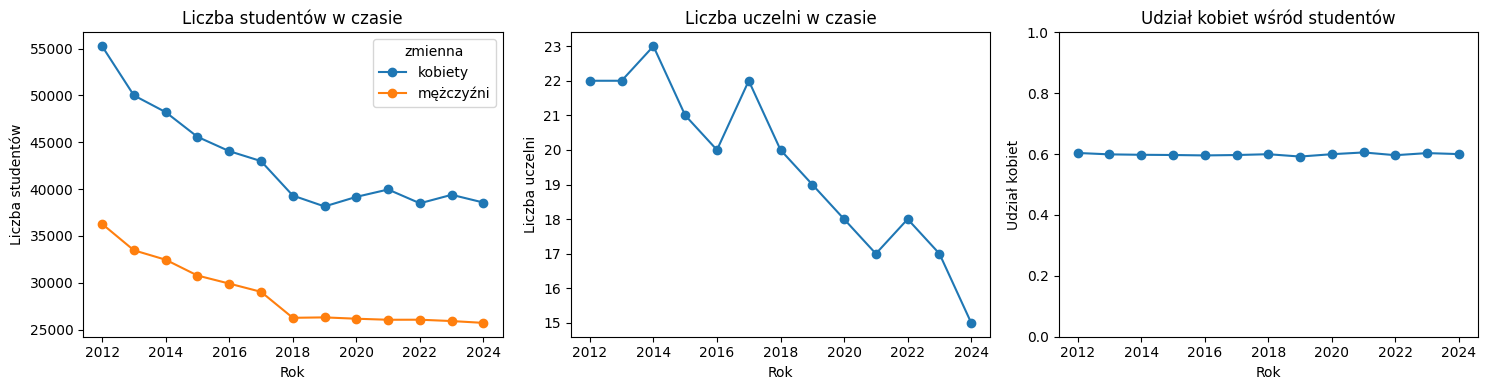

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# TODO: wykres 1 — kobiety i mężczyźni
szeroka[['kobiety', 'mężczyźni']].plot(ax=axes[0], marker='o')
axes[0].set_title('Liczba studentów w czasie')
axes[0].set_xlabel('Rok')
axes[0].set_ylabel('Liczba studentów')

# TODO: wykres 2 — uczelnie
szeroka['uczelnie'].plot(ax=axes[1], marker='o')
axes[1].set_title('Liczba uczelni w czasie')
axes[1].set_xlabel('Rok')
axes[1].set_ylabel('Liczba uczelni')

# TODO: wykres 3 — udział kobiet
szeroka['udzial_kobiet'].plot(ax=axes[2], marker='o')
axes[2].set_title('Udział kobiet wśród studentów')
axes[2].set_xlabel('Rok')
axes[2].set_ylabel('Udział kobiet')
axes[2].set_ylim(0, 1)

plt.tight_layout()
plt.show()

✍️ **Wnioski** (3 zdania): co się stało ze szkolnictwem wyższym w Łodzi w latach 2012–2024?

*Odpowiedź:*  
Liczba studentów na uczelniach wyższych w Łodzi w latach 2012-2024 miała wyraźną tendencję spadkową.  
Liczba uczelni w latach 2012-2024 miała tendencję spadkową, choć momentami liczba tych uczelni wzrastała np. w 2014 wzrosła liczba względem 2013 roku tak samo w 2017 roku był wzrost względem 2016 roku.  
Udział kobiet wśród studentów w latach 2012-2024 utrzymuje się na stabilnym poziomie około 60%.

## 1.6 Zadanie samodzielne: Twój zbiór z portalu Łodzi

Wybierz **inny** zbiór z [otwarte.miasto.lodz.pl](https://otwarte.miasto.lodz.pl) i przejdź te same kroki:

1. Podaj nazwę zbioru, link i datę pobrania.
2. Wczytaj plik (separator? kodowanie? przecinek dziesiętny?).
3. Ustal, czy dane są w formacie długim, czy szerokim; w razie potrzeby przekształć.
4. Sprawdź braki (`isna().sum()`) i spójność danych.
5. Policz statystyki zbiorcze.
6. Zrób 2–3 podpisane wykresy i napisz 2–3 zdania wniosków.

✍️ **Zbiór:** Ludność w wieku produkcyjnym w Łodzi · **link:** [https://otwarte.miasto.lodz.pl/ludnosc/](https://otwarte.miasto.lodz.pl/ludnosc/) · **data pobrania:** 27.10.2026

In [ ]:
# TODO: wczytanie i przegląd Twojego zbioru
# 2
df_ludnosc = pd.read_csv("ludnosc_w_wieku_produkcyjnym.csv", sep=';')

# TODO: wyświetl pierwsze wiersze, wymiary i typy kolumn
print(f"Pierwsze wiersze: \n{df_ludnosc.head()}")
# 4
print(f"\nBraki danych: \n{df_ludnosc.isna().sum()}")

# 3
print(f"\nTypy kolumn: \n{df_ludnosc.dtypes}")


Pierwsze wiersze: 
    id     name   rok  wartość                                zmienne
0  152  Ludność  1995   504530  Ludność w wieku produkcyjnym - ogółem
1  152  Ludność  1996   504488  Ludność w wieku produkcyjnym - ogółem
2  152  Ludność  1997   504603  Ludność w wieku produkcyjnym - ogółem
3  152  Ludność  1998   505587  Ludność w wieku produkcyjnym - ogółem
4  152  Ludność  1999   509574  Ludność w wieku produkcyjnym - ogółem

Braki danych: 
id         0
name       0
rok        0
wartość    0
zmienne    0
dtype: int64

Typy kolumn: 
id          int64
name       object
rok         int64
wartość     int64
zmienne    object
dtype: object


Statystyki zbiorcze:


zmienne,Ludność w wieku produkcyjnym - kobiety,Ludność w wieku produkcyjnym - mężczyźni,Ludność w wieku produkcyjnym - ogółem
count,31.00,31.00,31.00
mean,224695.16,227381.65,452076.81
std,32447.99,24282.74,56582.94
min,174934.00,183693.00,358627.00
25%,190601.00,205117.00,395718.00
50%,230981.00,237383.00,468364.00
75%,256741.00,248608.00,505095.00
max,259156.00,251532.00,510555.00


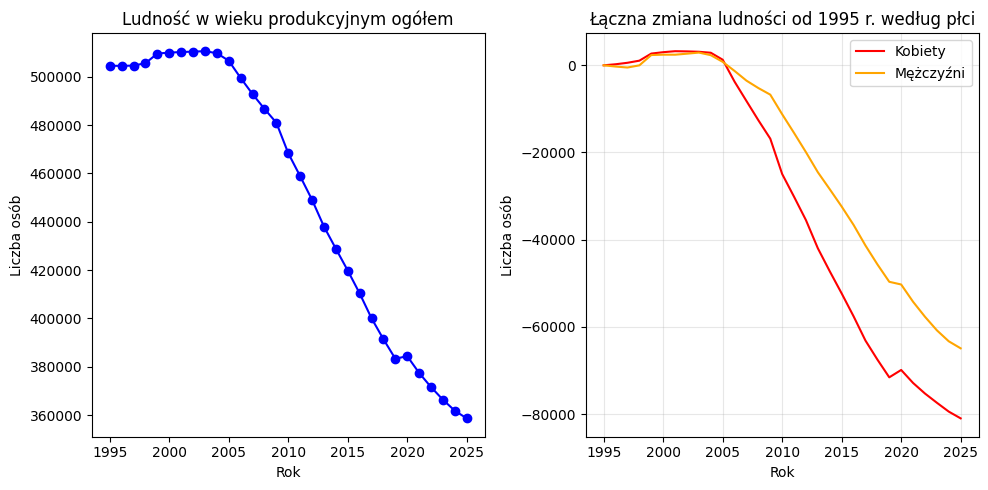

In [30]:
# TODO: przekształcenia, statystyki i wykresy
# statystyki
# 3
szeroka_ludnosc = df_ludnosc.pivot(index='rok', columns='zmienne', values='wartość').reset_index()
szeroka_ludnosc = szeroka_ludnosc.set_index('rok')

# 5
print("Statystyki zbiorcze:")
display(szeroka_ludnosc.describe())

# wykresy
# 6
fig, ax = plt.subplots(1, 2, figsize=(10, 5))

ax[0].plot(szeroka_ludnosc.index, szeroka_ludnosc["Ludność w wieku produkcyjnym - ogółem"], marker="o", color="blue")
ax[0].set_title('Ludność w wieku produkcyjnym ogółem')
ax[0].set_xlabel('Rok')
ax[0].set_ylabel('Liczba osób')

szeroka_ludnosc["zmiana_kobiety"] = szeroka_ludnosc["Ludność w wieku produkcyjnym - kobiety"].diff().fillna(0).cumsum()
szeroka_ludnosc["zmiana_mezczyzni"] = szeroka_ludnosc["Ludność w wieku produkcyjnym - mężczyźni"].diff().fillna(0).cumsum()

ax[1].plot(szeroka_ludnosc.index, szeroka_ludnosc["zmiana_kobiety"], color="red", linewidth=1.5, label="Kobiety")
ax[1].plot(szeroka_ludnosc.index, szeroka_ludnosc["zmiana_mezczyzni"], color="orange", linewidth=1.5, label="Mężczyźni")
ax[1].set_title("Łączna zmiana ludności od 1995 r. według płci")
ax[1].set_xlabel("Rok")
ax[1].set_ylabel("Liczba osób")
ax[1].grid(True, alpha=0.3)
ax[1].legend()

plt.tight_layout()
plt.show()

✍️ **Wnioski:**  
Liczba osób w wieku produkcyjnym w latach 1995-2004 była na stabilnym poziomie z widoczym lekkim wzrostem, natomiast od okolic 2005 roku widzimy gwałtowny spadek liczby ludności w wieku produkcyjnym w Łodzi, który trwa nieprzerwanie do 2025 roku.  
Trend spadkowy dotyczy obu płci, jednak skumulowana utrata ludności w wieku produkcyjnym jest wyraźnie większa u kobiet niż u mężczyzn. Z prawego wykresu możemy zauważyć, że do 2025 roku strata sięga około 80 tys. kobiet w wieku produkcyjnym względem 1995 roku, gdzie w tym samym czasie ubytek mężczyzn sięga około 65 tys.

---
# Część 2. Wartości odstające — dane o pacjentach

Zbiór: 3000 pacjentów z kolumnami `age` (wiek), `bmi`, `avg_glucose_level` (średni poziom glukozy we krwi, mg/dl), `hypertension`, `heart_disease`, `work_type` (rodzaj pracy), `smoking_status` (palenie), `stroke` (udar: 1/0) i kilkoma innymi.

> ⚠️ To **dane syntetyczne** — wygenerowane i celowo „zepsute” do ćwiczeń. Nie wyciągamy z nich wniosków medycznych.
>
> Źródło: deepsense.ai, *EDA Benchmark*, zadanie `identify-unusual-values` ([github.com/deepsense-ai/eda-benchmark](https://github.com/deepsense-ai/eda-benchmark)), licencja CC BY-NC-ND 4.0.

Plan — od najprostszej metody do najbardziej złożonej:

| Krok | Metoda |
|---|---|
| 1 | wartości niemożliwe — progi z wiedzy dziedzinowej |
| 2 | wartości skrajne w jednej zmiennej — wykresy, potem IQR, z-score, MAD |
| 3 | nielogiczne kombinacje kategorii — reguły |
| 4 | nietypowe kombinacje liczb — odległość od środka |
| 5 | decyzja: co zrobić z każdą grupą |

In [13]:
URL = ("https://raw.githubusercontent.com/deepsense-ai/eda-benchmark/main/"
       "tasks/identify-unusual-values/environment/dataset/synthetic_stroke_data.csv")

pacjenci = pd.read_csv(URL)
oryginal = pacjenci.copy()      # kopia surowych danych — przyda się na końcu
pacjenci.head()

,patient_id,gender,age,hypertension,heart_disease,ever_married,work_type,residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,A456281,Male,25.00,0,0,False,student,Urban,77.47,35.66,formerly smoked,0
1,A730553,Male,16.00,0,0,True,student,Urban,83.78,34.76,never smoked,0
2,A800980,Male,19.00,0,0,True,Private,Urban,91.65,25.38,never smoked,0
3,A433166,Male,35.00,0,0,True,Self-employed,Urban,97.09,21.26,never smoked,0
4,A114521,Male,15.00,0,0,True,student,Urban,89.17,22.27,formerly smoked,0


## 2.0 Pierwszy rzut oka

Wyświetl statystyki opisowe kolumn liczbowych `age`, `bmi`, `avg_glucose_level` i narysuj ich histogramy.

,age,bmi,avg_glucose_level
count,3000.00,3000.00,3000.00
mean,45.25,26.29,134.00
std,20.83,15.88,181.27
min,0.67,-5.20,-21.40
25%,28.00,21.28,85.59
50%,49.00,24.70,101.40
75%,63.00,28.88,127.43
max,80.00,105.60,1254.60


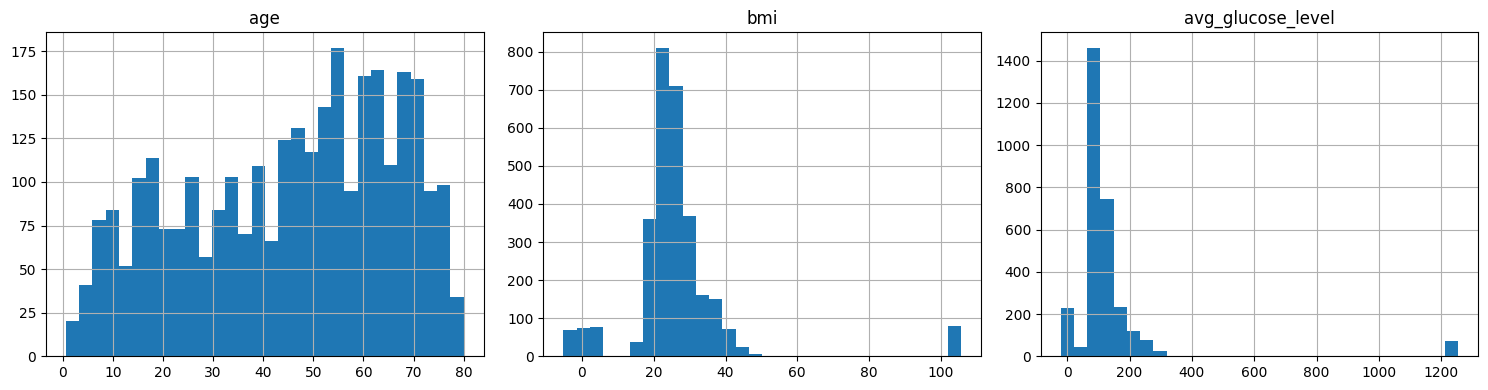

In [14]:
from re import L


LICZBOWE = ["age", "bmi", "avg_glucose_level"]

# TODO: statystyki opisowe
display(pacjenci[LICZBOWE].describe())

# TODO: histogramy (np. pacjenci[LICZBOWE].hist(...))
pacjenci[LICZBOWE].hist(bins=30, figsize=(15, 4), layout=(1, 3))
plt.tight_layout()
plt.show()


✍️ **Pytanie:** Które wartości minimalne i maksymalne są w ogóle *możliwe* u człowieka?

*Odpowiedź:*  
Analizując wygenerowane statystyki, możemy zauważyć niemożliwe medycznie wartości np. widzimy ujemne wartości BMI (-5.20) oraz glukozy (-21.40), co jest fizycznie niemożliwe do uzyskania. Tak samo skrajne odchylenia na histogramach np. słupek glukozy powyżej 1200. 

## 2.1 Krok 1: wartości niemożliwe

Przyjmujemy progi:

| Zmienna | Zakres możliwy |
|---|---|
| `bmi` | 10–60 |
| `avg_glucose_level` | 20–800 mg/dl |
| `age` | 0–120 lat |

Wartości spoza zakresu to **szum techniczny**, a nie rzadcy pacjenci — zamieniamy je na `NaN`.

1. Utwórz maski `zle_bmi`, `zla_glukoza`, `zly_wiek` (przyda się `Series.between`).
2. Policz, ile wartości jest niemożliwych w każdej kolumnie i ilu pacjentów ma co najmniej jedną taką wartość.
3. Zamień niemożliwe wartości na `NaN`.

In [15]:
# TODO: maski
zle_bmi = ~pacjenci["bmi"].between(10, 60)
zla_glukoza = ~pacjenci["avg_glucose_level"].between(20, 800)
zly_wiek = ~pacjenci["age"].between(0, 120)

# TODO: liczebności
print(f"Niemożliwe BMI: {zle_bmi.sum()}")
print(f"Niemożliwa glukoza: {zla_glukoza.sum()}")
print(f"Niemożliwy wiek: {zly_wiek.sum()}")

zli_pacjenci = zle_bmi | zla_glukoza | zly_wiek
print(f"Pacjenci z co najmniej jedną złą wartością: {zli_pacjenci.sum()}")

# TODO: zamiana na NaN
pacjenci.loc[zle_bmi, "bmi"] = np.nan
pacjenci.loc[zla_glukoza, "avg_glucose_level"] = np.nan
pacjenci.loc[zly_wiek, "age"] = np.nan


Niemożliwe BMI: 300
Niemożliwa glukoza: 300
Niemożliwy wiek: 0
Pacjenci z co najmniej jedną złą wartością: 560


,age,bmi,avg_glucose_level
count,3000.00,2700.00,2700.00
mean,45.25,26.12,116.84
std,20.83,5.84,44.45
min,0.67,13.57,44.76
25%,28.00,21.94,89.47
50%,49.00,24.98,103.09
75%,63.00,28.85,127.84
max,80.00,47.62,332.91


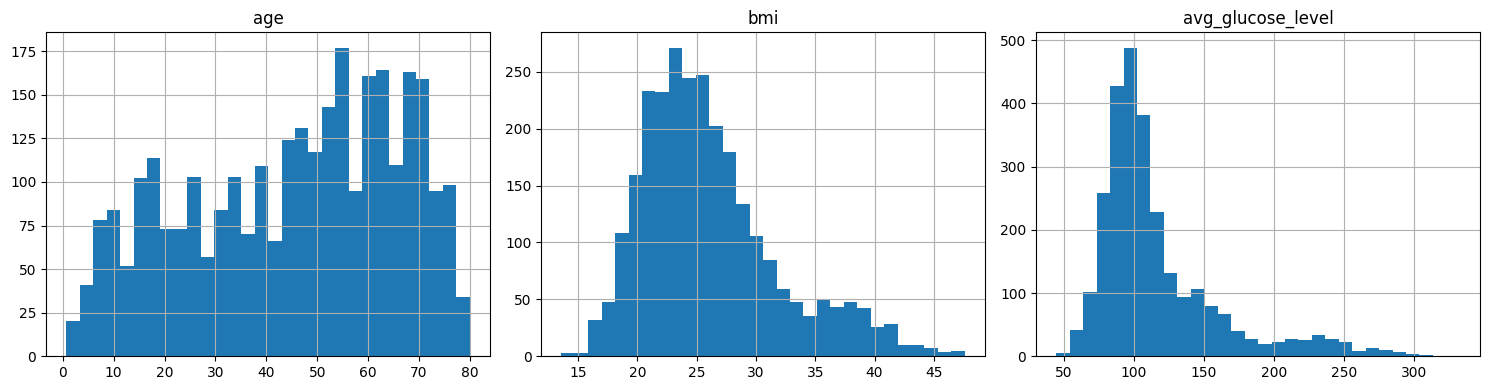

In [16]:
# TODO: ponownie statystyki opisowe i histogramy — co się zmieniło?
display(pacjenci[LICZBOWE].describe())

pacjenci[LICZBOWE].hist(bins=30, figsize=(15, 4), layout=(1, 3))
plt.tight_layout()
plt.show()

Pozbyliśmy się niemożliwych wartości. Możemy to zobaczyć dla bmi i avg_glucose_level, gdzie ich liczba spadała z 3000 na 2700, co oznacza, że błędne dane zostały zamienione na NaN i nie zaburzają statystyk.

## 2.2 Krok 2a: wartości skrajne w jednej zmiennej — wykresy

Zanim cokolwiek policzysz, **obejrzyj** dane.

1. Narysuj obok siebie poziome wykresy pudełkowe dla `bmi` i `avg_glucose_level` (`plt.subplots(1, 2)`, `ax.boxplot(..., orientation="horizontal")`). Pamiętaj o `dropna()`.
2. Narysuj obok siebie dwa wykresy punktowe: `age` × `avg_glucose_level` i `age` × `bmi`.

Podpisz osie (z jednostkami) i nadaj tytuły.

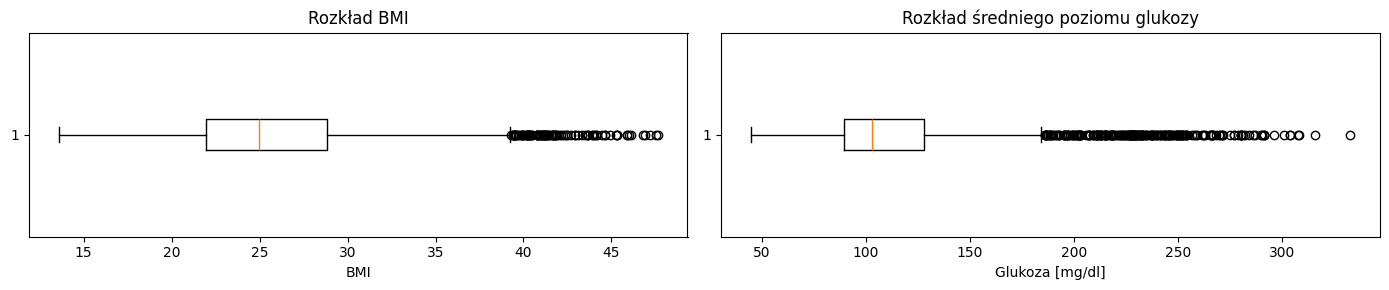

In [17]:
from sqlalchemy import column


fig, axes = plt.subplots(1, 2, figsize=(14, 3))

# TODO: wykresy pudełkowe bmi i glukozy
axes[0].boxplot(pacjenci['bmi'].dropna(), orientation='horizontal')
axes[0].set_title('Rozkład BMI')
axes[0].set_xlabel('BMI')

axes[1].boxplot(pacjenci['avg_glucose_level'].dropna(), orientation='horizontal')
axes[1].set_title('Rozkład średniego poziomu glukozy')
axes[1].set_xlabel('Glukoza [mg/dl]')

plt.tight_layout()
plt.show()

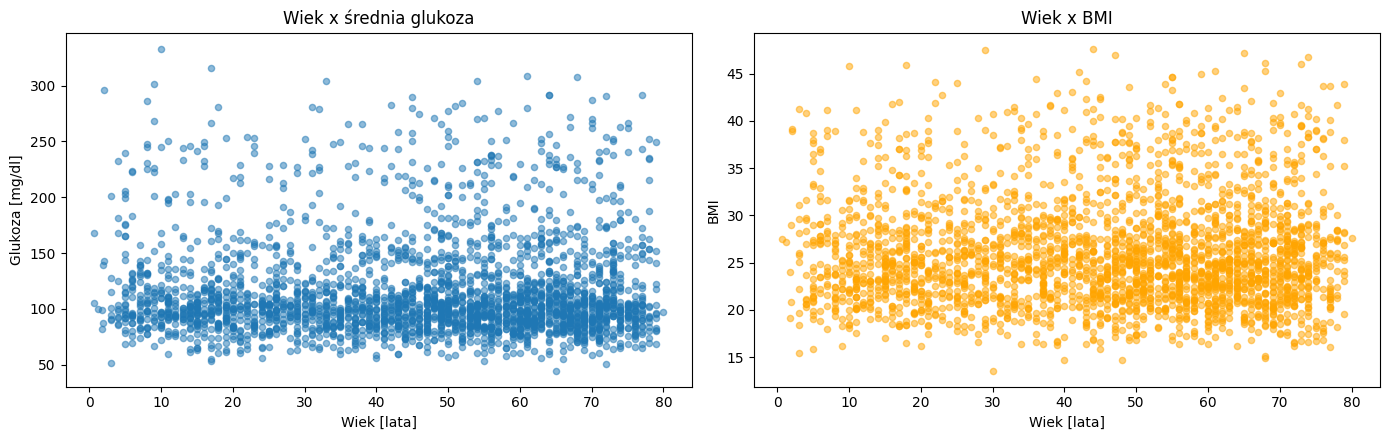

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# TODO: wykresy punktowe age × glukoza i age × bmi
pacjenci.plot.scatter(x='age', y='avg_glucose_level', ax=axes[0], alpha=0.5)
axes[0].set_title('Wiek x średnia glukoza')
axes[0].set_xlabel('Wiek [lata]')
axes[0].set_ylabel('Glukoza [mg/dl]')

pacjenci.plot.scatter(x='age', y='bmi', ax=axes[1], alpha=0.5, color='orange')
axes[1].set_title('Wiek x BMI')
axes[1].set_xlabel('Wiek [lata]')
axes[1].set_ylabel('BMI')

plt.tight_layout()
plt.show()

✍️ **Pytania:**
1. Dla której zmiennej jest więcej punktów poza wąsami? Czy leżą po obu stronach pudełka, czy tylko po jednej?  
2. Na wykresie punktowym: czy wysokie wartości glukozy występują tylko w określonym wieku? Czy 10-latek ze średnią glukozą ponad 300 mg/dl to błąd, czy rzadki przypadek?

*Odpowiedź:*  
1. Więcej punktów poza wąsami znajduje się na wykresie dla zmiennej 'avg_glucose_level'. Punkty leżą tylko po prawej stronie pudełka.  
2. Wysokie wartości glukozy np. powyżej 200 mg/dl występują w każdym wieku. 10-latek ze średnią glukozą ponad 300 mg/dl to raczej rzadki, ale medycznie możliwy przypadek (np. przy zaawansowanej cukrzycy typu 1), a nie błąd wprowadzania danych, ponieważ takie wartości znajdują się w założonym przedziale 20-800 mg/dl.

## 2.3 Krok 2b: wartości skrajne w jednej zmiennej — metody liczbowe

Napisz trzy funkcje, które dla kolumny `s` zwracają maskę (`True` = wartość odstająca):

- `maska_iqr(s, k=1.5)` — poza $[Q_1 - k \cdot IQR,\; Q_3 + k \cdot IQR]$,
- `maska_z(s, prog=3)` — $|z| > prog$, gdzie $z = (x - \bar{x}) / s$,
- `maska_mad(s, prog=3.5)` — odporny z-score $|0{,}6745 \cdot (x - \text{med}) / \text{MAD}| > prog$.

Braki (`NaN`) nie powinny być oznaczane jako odstające.

In [19]:
def maska_iqr(s, k=1.5):
    # TODO
    q1 = s.quantile(0.25)
    q3 = s.quantile(0.75)
    iqr = q3 - q1
    dolna = q1 - k * iqr
    gorna = q3 + k * iqr

    return (s < dolna) | (s > gorna)

def maska_z(s, prog=3):
    # TODO
    z = (s - s.mean()) / s.std()
    return z.abs() > prog

def maska_mad(s, prog=3.5):
    # TODO
    med = s.median()
    mad = (s - med).abs().median()
    z_m = 0.6745 * (s - med) / mad
    return z_m.abs() > prog

Zbuduj tabelę porównawczą: wiersze = zmienne (`age`, `bmi`, `avg_glucose_level`), kolumny = metody (IQR 1,5, IQR 3, z-score, MAD), wartości = liczba wykrytych obserwacji. Dodaj kolumnę ze **skośnością** (`skew`).

In [20]:
# TODO: tabela porównawcza `porownanie`
wyniki = {}
for col in LICZBOWE:
    s = pacjenci[col]
    wyniki[col] = {
        'IQR 1,5': maska_iqr(s, k=1.5).sum(),
        'IQR 3': maska_iqr(s, k=3).sum(),
        'z-score': maska_z(s, prog=3).sum(),
        'MAD': maska_mad(s, prog=3.5).sum(),
        'skew': s.skew()
    }

porownanie = pd.DataFrame(wyniki).T
porownanie

,"IQR 1,5",IQR 3,z-score,MAD,skew
age,0.00,0.00,0.00,0.00,-0.33
bmi,100.00,0.00,23.00,33.00,0.99
avg_glucose_level,235.00,81.00,62.00,223.00,1.80


✍️ **Pytanie:** Dlaczego dla glukozy metody dają tak różne wyniki, a dla wieku żadna nic nie wykrywa? Spójrz na skośność i histogramy.

*Odpowiedź:*  
Dla glukozy różnice wynikają z jej silnej prawoskośności (długi ogon rozkładu). Klasyczny z-score jest nieodporny na wartości odstające, które same zawyżają odchylenie standardowe (efekt maskowania), przez co wykrywa ich mniej niż metody odporne takie jak MAD czy IQR. Wiek natomiast ma rozkład  małej skośności bez długich ogonów, przez co żadne punkty nie oddalają się od środka na tyle, by przekroczyć ustalone progi którejkolwiek z metod.

### Wykres: zaznacz wartości odstające

Powtórz wykres punktowy `age` × `avg_glucose_level`, ale tym razem:

- zaznacz innym kolorem pacjentów, których glukoza jest odstająca według `maska_iqr` (i podaj ich liczbę w legendzie),
- narysuj poziomą linię przerywaną na górnej granicy $Q_3 + 1{,}5 \cdot IQR$ (`ax.axhline`).

Sprawdź: czy liczba punktów nad linią zgadza się z liczbą punktów poza wąsem na wykresie pudełkowym?

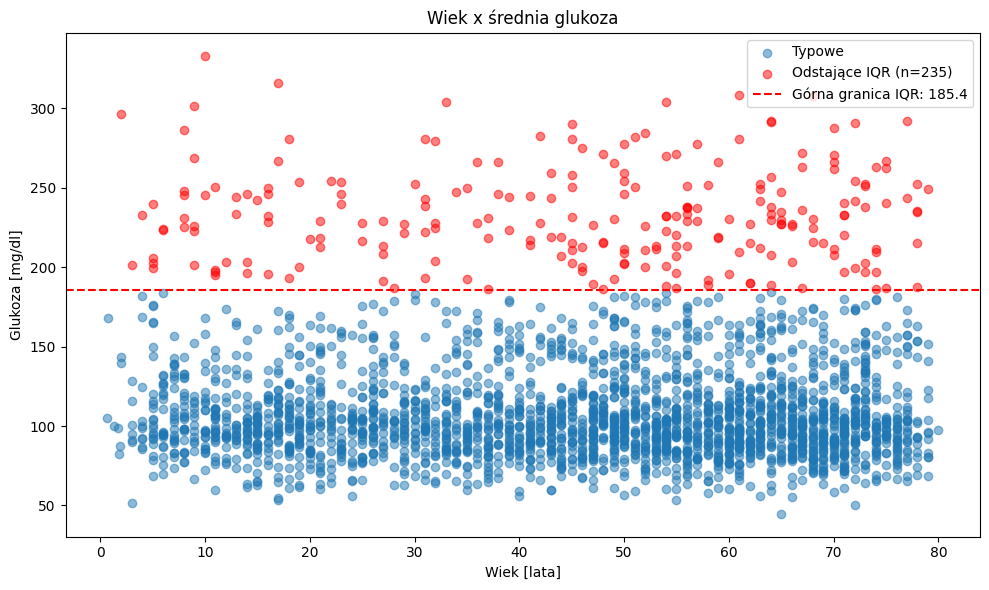

In [21]:
# TODO: wykres punktowy z zaznaczonymi wartościami odstającymi
glukoza = pacjenci['avg_glucose_level']
odstajace = maska_iqr(glukoza, k=1.5)

q1 = glukoza.quantile(0.25)
q3 = glukoza.quantile(0.75)
gorna = q3 + 1.5 * (q3 - q1)

fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(pacjenci.loc[~odstajace, 'age'], pacjenci.loc[~odstajace, 'avg_glucose_level'], alpha=0.5, label='Typowe')
ax.scatter(pacjenci.loc[odstajace, 'age'], pacjenci.loc[odstajace, 'avg_glucose_level'], color='red', alpha=0.5, label=f'Odstające IQR (n={odstajace.sum()})')

ax.axhline(float(gorna), color='red', linestyle='--', label=f'Górna granica IQR: {gorna:.1f}')

ax.set_title('Wiek x średnia glukoza')
ax.set_xlabel('Wiek [lata]')
ax.set_ylabel('Glukoza [mg/dl]')
ax.legend()

plt.tight_layout()
plt.show()

### Czy wartość odstająca niesie informację?

Wysoki poziom glukozy może być związany z udarem. Porównaj odsetek udarów (`stroke`) wśród pacjentów z glukozą odstającą (IQR 1,5) i wśród pozostałych. Narysuj wykres pudełkowy glukozy w podziale na `stroke`.

Odsetek udarów u pacjentów z glukozą odstającą: 21.7%
Odsetek udarów u pacjentów z typową glukozą: 21.9%


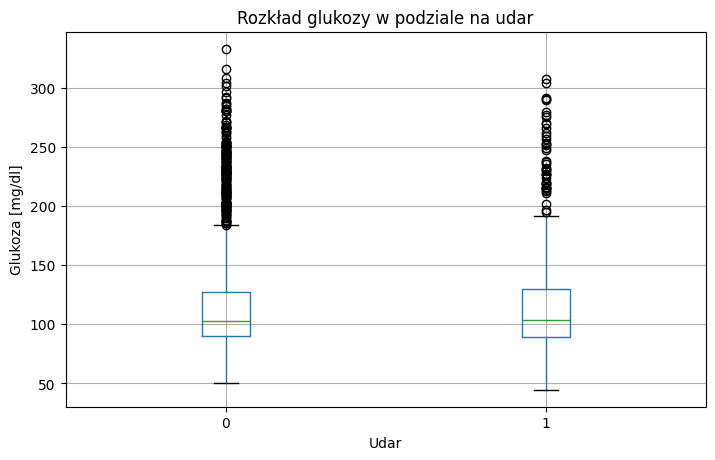

In [22]:
# TODO: odsetek udarów w obu grupach
odsetek_odstajace = pacjenci.loc[odstajace, 'stroke'].mean() * 100
odsetek_typowe = pacjenci.loc[~odstajace, 'stroke'].mean() * 100

print(f"Odsetek udarów u pacjentów z glukozą odstającą: {odsetek_odstajace:.1f}%")
print(f"Odsetek udarów u pacjentów z typową glukozą: {odsetek_typowe:.1f}%")

# TODO: boxplot glukozy w podziale na stroke
pacjenci.boxplot(column='avg_glucose_level', by='stroke', figsize=(8, 5))
plt.title('Rozkład glukozy w podziale na udar')
plt.suptitle('')
plt.xlabel('Udar')
plt.ylabel('Glukoza [mg/dl]')
plt.show()

✍️ **Pytanie:** Czy pacjentów z wysoką glukozą należy usunąć z danych, jeśli chcemy przewidywać udar?

*Odpowiedź:*  
Nie należy usuwać z danych pacjentów z wysoką glukozą, ponieważ wysoki poziom glukozy (często oznaczający cukrzycę) nie jest błędem technicznym, lecz prawdziwą cechą pacjenta, która daje nam bardzo ważną informację z perspektywy medycznej. Usunięcie takich pacjentów z danych pozbawiłoby model cennych informacji, ponieważ według wyliczeń w grupie o bardzo wysokim poziomie glukozy odsetek występowania udarów jest znacznie wyższy.

## 2.4 Krok 3: nielogiczne kombinacje kategorii

Każda wartość osobno może być poprawna („dziecko”, „pali”), a niemożliwa jest dopiero ich kombinacja.

1. Zrób tabelę krzyżową `work_type` × `smoking_status` (`pd.crosstab`). Co jest podejrzane?
2. Utwórz maski:
   - `dziecko_pali` — `work_type == "children"` i `smoking_status` to `"smokes"` lub `"formerly smoked"`,
   - `maluch_student` — wiek ≤ 3 lata i `work_type == "student"`.
3. Wyświetl znalezionych pacjentów.

In [26]:
# TODO: tabela krzyżowa
display(pd.crosstab(pacjenci['work_type'], pacjenci['smoking_status']))

# TODO: maski
dziecko_pali = (
    (pacjenci['work_type'] == 'children') & pacjenci['smoking_status'].isin(['smokes', 'formerly smoked'])
)

maluch_student = (
    (pacjenci['age'] <= 3) & (pacjenci['work_type'] == 'student')
)

print(f"Liczba palących dzieci: {dziecko_pali.sum()}")
print(f"Liczba maluchów-studentów: {maluch_student.sum()}")

display(pacjenci[dziecko_pali | maluch_student])


smoking_status,Unknown,formerly smoked,never smoked,smokes
work_type,,,,
Govt_job,16,63,94,67
Never_worked,1,30,36,35
Private,76,440,585,445
Self-employed,18,137,166,131
children,17,0,274,15
student,22,67,190,75


Liczba palących dzieci: 15
Liczba maluchów-studentów: 1


,patient_id,gender,age,hypertension,heart_disease,ever_married,work_type,residence_type,avg_glucose_level,bmi,smoking_status,stroke
52,A582477,Female,1.80,0,0,False,student,Rural,82.20,24.05,formerly smoked,0
111,A678646,Female,9.00,0,0,False,children,Rural,96.59,22.24,smokes,0
290,A844121,Male,13.00,0,0,False,children,Urban,163.31,20.14,smokes,0
336,A135365,Female,12.00,0,0,False,children,Urban,135.59,27.15,smokes,0
352,A810636,Male,14.00,0,0,False,children,Rural,203.26,NaN,smokes,0
361,A843508,Male,2.00,0,0,False,children,Urban,143.14,39.11,smokes,0
578,A161666,Male,3.00,0,0,False,children,Urban,NaN,15.47,smokes,0
600,A623587,Male,10.00,0,0,False,children,Urban,NaN,20.93,smokes,0
613,A892803,Male,13.00,0,0,False,children,Urban,132.17,25.04,smokes,0
741,A560170,Male,13.00,0,0,False,children,Urban,243.95,25.59,smokes,0


✍️ **Pytanie:** Czy IQR albo z-score mogłyby wykryć te przypadki? Dlaczego?

*Odpowiedź:*  
Nie, ani IQR ani z-score nie są w stanie wykryć tych przypadków, ponieważ badają tylko pojedyncze zmienne liczbowe. Tutaj każda kategoria z osobna jest poprawna, a błędem jest dopiero ich nielogiczna kombinacja, do której wykrycia potrzebne są reguły z wiedzy dziedzinowej.

## 2.5 Krok 4: nietypowe kombinacje liczb — odległość od środka

Liczymy kwadrat **odległości euklidesowej** każdego pacjenta od środka danych, po standaryzacji cech:

$$d^2 = \sum_j \left(\frac{x_j - \bar{x}_j}{s_j}\right)^2$$

Dla danych o rozkładzie normalnym $d^2$ ma rozkład $\chi^2$ z $p$ stopniami swobody ($p$ = liczba cech), więc próg bierzemy z kwantyla 0,99.

1. Weź kolumny `LICZBOWE` bez braków (`dropna`) → `X`.
2. Wystandaryzuj je i policz `d2`.
3. Wyznacz próg `chi2.ppf(0.99, df=3)` i policz, ilu pacjentów go przekracza.
4. Sprawdź, **która cecha** ma największy udział w $d^2$ u tych pacjentów (`idxmax(axis=1)` na kwadratach z-score'ów).

In [34]:
from scipy.stats import chi2

# TODO
X = pacjenci[['age', 'bmi', 'avg_glucose_level']].dropna()
Z = (X - X.mean()) / X.std()
d2 = (Z ** 2).sum(axis=1)
prog = chi2.ppf(0.99, df=3)
odstajacy_euklides = d2 > prog
print(f"Próg: {prog:.2f}")
print(f"Liczba pacjentów przekraczających próg: {odstajacy_euklides.sum()}")

najwiekszy_udzial = (Z ** 2)[odstajacy_euklides].idxmax(axis=1)
print("\nCecha mająca największy udział w d2 u pacjentów odstających:")
display(najwiekszy_udzial.value_counts())




Próg: 11.34
Liczba pacjentów przekraczających próg: 73

Cecha mająca największy udział w d2 u pacjentów odstających:


,count
avg_glucose_level,54
bmi,19


Glukoza jest silnie prawoskośna, więc odległość wskazuje głównie jej długi ogon. Powtórz obliczenia po zlogarytmowaniu glukozy (`np.log`) i porównaj liczbę odstających. Narysuj wykres punktowy `bmi` × `avg_glucose_level`, zaznaczając pacjentów odstających po transformacji.

Liczna pacjentów odstających po zlogarytmowaniu: 31


,age,bmi,avg_glucose_level
age,1.00,0.02,0.01
bmi,0.02,1.00,-0.02
avg_glucose_level,0.01,-0.02,1.00


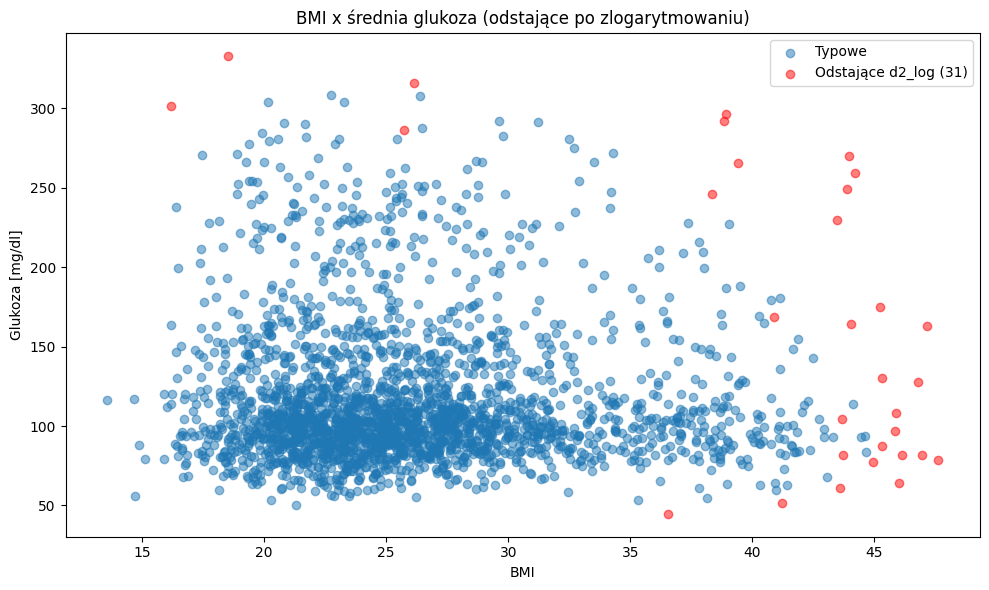

In [39]:
# TODO: X_log, Z_log, d2_log i liczba odstających
X_log = X.assign(avg_glucose_level=np.log(X['avg_glucose_level']))
Z = (X_log - X_log.mean()) / X_log.std()
d2_log = (Z ** 2).sum(axis=1)
odstajacy_log = d2_log > prog
print(f"Liczna pacjentów odstających po zlogarytmowaniu: {odstajacy_log.sum()}")
display(X.corr())

# TODO: wykres punktowy
fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(X.loc[~odstajacy_log, 'bmi'], X.loc[~odstajacy_log, 'avg_glucose_level'], alpha=0.5, label='Typowe')
ax.scatter(X.loc[odstajacy_log, 'bmi'], X.loc[odstajacy_log, 'avg_glucose_level'], color='red', alpha=0.5, label=f'Odstające d2_log ({odstajacy_log.sum()})')

ax.set_title('BMI x średnia glukoza (odstające po zlogarytmowaniu)')
ax.set_xlabel('BMI')
ax.set_ylabel('Glukoza [mg/dl]')
ax.legend()

plt.tight_layout()
plt.show()


✍️ **Pytanie:** Wiek, BMI i glukoza są tu prawie nieskorelowane (sprawdź `X.corr()`). Czy w takiej sytuacji odległość Mahalanobisa dałaby coś więcej niż euklidesowa?

*Odpowiedź:*  
Nie. Dla nieskorelowanych zmiennych odległość Mahalanobisa daje takie same wyniki jak euklidesowa. Wnosi ona nowe informacje tylko przy wyraźnej korelacji, dlatego w tym przypadku w zupełności wystarczy standardowa odległość euklidesowa.


### Dla chętnych: Isolation Forest

Użyj `sklearn.ensemble.IsolationForest` (`contamination=0.01`, `random_state=0`) na `X_log`. Ilu pacjentów wskazuje jednocześnie Isolation Forest i odległość `d2_log`?

In [40]:
# TODO (dla chętnych)
from sklearn.ensemble import IsolationForest

iso = IsolationForest(contamination=0.01, random_state=0)
etykiety = iso.fit_predict(X_log)

odstajacy_iso = etykiety == -1
czesc_wspolna = odstajacy_iso & odstajacy_log

print(f"Odstający według Isolation Forest: {odstajacy_iso.sum()}")
print(f"Pacjenci wskazani przez Isolation Forest i d2_log: {czesc_wspolna.sum()}")



Odstający według Isolation Forest: 25
Pacjenci wskazani przez Isolation Forest i d2_log: 19


## 2.6 Krok 5: podsumowanie i decyzja

Zbierz wyniki wszystkich kroków w jednej ramce `flagi` (jeden wiersz na pacjenta, indeks jak w `oryginal`) z kolumnami logicznymi:

- `niemozliwa_wartosc` (krok 1),
- `glukoza_iqr` (krok 2, IQR 1,5 dla glukozy),
- `nielogiczna_kategoria` (krok 3),
- `odlegly_od_srodka` (krok 4, `d2_log`; pacjenci bez obliczonej odległości → `False`).

Policz, ilu pacjentów ma każdą flagę i ilu ma co najmniej jedną.

In [44]:
# TODO: ramka flagi
flagi = pd.DataFrame({
    'niemozliwa_wartosc': zli_pacjenci,
    'glukoza_iqr': maska_iqr(pacjenci['avg_glucose_level'], k=1.5),
    'nielogiczna_kategoria': dziecko_pali | maluch_student,
    'odlegly_od_srodka': odstajacy_log.reindex(pacjenci.index, fill_value=False)
})

print(f"Liczba pacjentów z poszczególnymi flagami:")
display(flagi.sum())

co_najmniej_jedna = flagi.any(axis=1).sum()
print(f"\nLiczba pacjentów z co najmniej jedną flagą: {co_najmniej_jedna}")

Liczba pacjentów z poszczególnymi flagami:


,0
niemozliwa_wartosc,560
glukoza_iqr,235
nielogiczna_kategoria,16
odlegly_od_srodka,31



Liczba pacjentów z co najmniej jedną flagą: 806


✍️ **Decyzja:** dla każdej grupy zaproponuj strategię i uzasadnij ją jednym zdaniem.

| Grupa | Strategia (poprawić / NaN / usunąć / przyciąć / log / zostawić / flaga) | Uzasadnienie |
|---|---|---|
| wartości niemożliwe | NaN / usunąć | Są to błędy wprowadzania danych np. ujemne BMI, które są fizycznie niemożliwe. |
| wysoka glukoza (IQR) | zostawić / log / flaga | Wartości medycznie poprawne (np. cukrzyca typu 1) niosące cenne informacje o wysokim ryzyku wystąpienia udaru. |
| nielogiczne kategorie | NaN / usunąć | Pojedyncze wartości są poprawne, ale ich kombinacje (np. palący 3-latek) są błędem w danych. |
| odlegli od środka | flaga / zostawić | Są to rzadkie, ale możliwe wielowymiarowe przypadki, które warto oflagować i zostawić do ewentualnej analizy. |